# Where did the animal spend time?

**Question:** How is time distributed across the arena, and which locations
were never visited during this recording?

**You will need:** Tracking positions, their timestamps, and the arena
boundary. This notebook supplies a simulated two-minute open-field recording.
It runs independently and requires no downloads.

**Estimated time**: 15-20 minutes

**Prerequisites**: None; basic NumPy is helpful.

We will calculate occupancy, measure time in the center, and compare spatial
bin sizes before using the same approach for firing-rate maps.

Run cells in order in a Python environment with `neurospatial` installed.
Keep `_style.py` beside this notebook; launching Jupyter from the repository
root or `examples/` both work. See the
[installation guide](https://edeno.github.io/neurospatial/getting-started/installation/)
for setup.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from shapely.geometry import box

from neurospatial import Environment
from neurospatial.ops.mapping import regions_to_mask
from neurospatial.regions import Regions

_here = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
if not (_here / "_style.py").exists() and (_here / "examples" / "_style.py").exists():
    _here = _here / "examples"
if str(_here) not in sys.path:
    sys.path.insert(0, str(_here))
from _style import apply_style

apply_style(figsize=(11, 5))

## 1. Start with a short open-field recording

The arena is a 60 × 60 cm square. We generate a random walk at 20 Hz and keep
it within part of the arena so that some accessible locations remain unvisited.
This gives us a simple example of uneven spatial sampling.

`positions` contains one `(x, y)` pair per tracking sample, in centimeters.
`times` contains the corresponding timestamps in seconds. The checks below
confirm that the arrays match and that time increases throughout the recording.

In [2]:
rng = np.random.default_rng(101)
times = np.arange(2401, dtype=float) / 20.0
positions = np.empty((len(times), 2))
positions[0] = [25.0, 30.0]
lower, upper = np.array([5.0, 5.0]), np.array([45.0, 55.0])
span = upper - lower
for sample in range(1, len(times)):
    proposed = positions[sample - 1] + rng.normal(0.0, 1.2, size=2)
    positions[sample] = lower + np.abs((proposed - lower + span) % (2 * span) - span)

In [3]:
assert positions.shape == (len(times), 2)
assert np.isfinite(times).all() and np.isfinite(positions).all()
assert np.all(np.diff(times) > 0)
print(f"Tracking: {len(times):,} samples over {times[-1] - times[0]:.1f} s")
print(f"Median time between tracking samples: {np.median(np.diff(times)):.3f} s")

Tracking: 2,401 samples over 120.0 s
Median time between tracking samples: 0.050 s


## 2. Divide the arena into 5 cm spatial bins

We include the whole arena when defining spatial bins. An unvisited part of
the floor should remain visible in an occupancy map. Here a 12 × 12 array of
`True` values tells `from_grid_mask()` to include every 5 × 5 cm square.

For comparison, `from_samples()` keeps only bins containing tracking samples.
That is useful when the boundary is unknown, but it cannot distinguish a wall
from accessible space the animal did not visit. Both methods return an
`Environment`, which holds the bins and their neighbor connections.

Bins covering the whole arena: 144
Bins containing recorded positions: 66


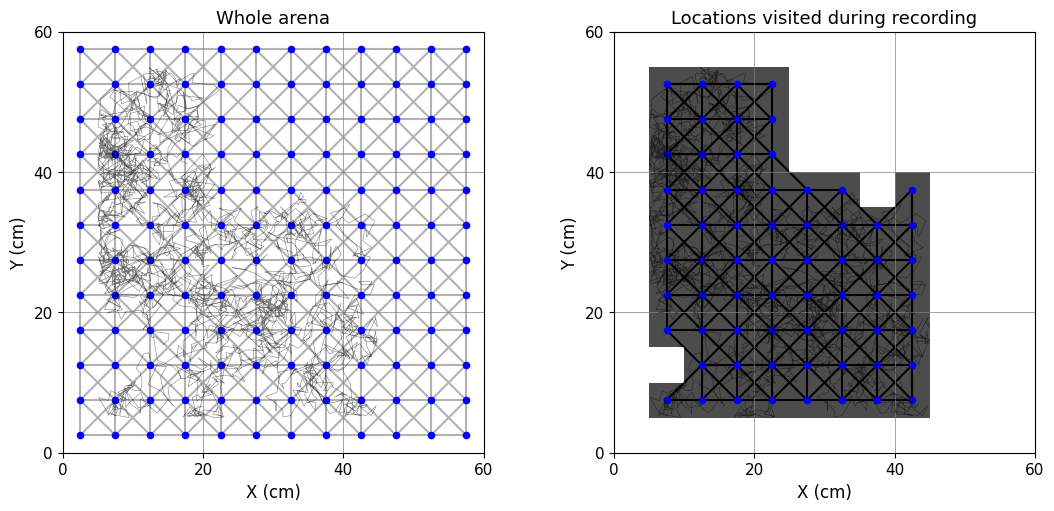

In [4]:
edges = np.arange(0.0, 60.0 + 5.0, 5.0)
env = Environment.from_grid_mask(
    active_mask=np.ones((12, 12), dtype=bool),
    grid_edges=(edges, edges),
    name="Known square arena",
)
env = env.with_metadata(units="cm", frame="arena")
sampled_env = Environment.from_samples(
    positions,
    bin_size=5.0,
    dimension_ranges=[(0.0, 60.0), (0.0, 60.0)],
    bin_count_threshold=1,
    name="Sampled space",
    units="cm",
    frame="arena",
)
print(f"Bins covering the whole arena: {env.n_bins}")
print(f"Bins containing recorded positions: {sampled_env.n_bins}")

fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
for ax, space, title in zip(
    axes, [env, sampled_env], ["Whole arena", "Locations visited during recording"]
):
    space.plot(ax=ax, show_connectivity=True)
    ax.plot(positions[:, 0], positions[:, 1], color="black", lw=0.4, alpha=0.5)
    ax.set(xlim=(0, 60), ylim=(0, 60), title=title, xlabel="X (cm)", ylabel="Y (cm)")
    ax.set_xticks([0, 20, 40, 60])
    ax.set_yticks([0, 20, 40, 60])
    ax.tick_params(bottom=True, left=True, labelbottom=True, labelleft=True)
    ax.set_aspect("equal")
plt.show()

Both panels show the same trajectory. The dots mark bin centers, and the
connecting lines define neighboring bins for later spatial analyses. The
upper-right part of the floor remains in the whole-arena model even though
the trajectory never enters it. We use that model for the occupancy map below.

## 3. Check which recorded positions are inside the arena

`bin_at()` assigns each position to a spatial bin. Compare a visited location,
an unvisited corner, and a point outside the arena. The unvisited corner has
a bin in the whole-arena model, while the outside point returns `-1`.

Keep indices greater than or equal to zero when selecting values from an
array. NumPy uses `-1` to select its last element, so it must be excluded.

In [5]:
queries = np.array([[25.0, 30.0], [57.5, 57.5], [65.0, 10.0]])
known_bins = env.bin_at(queries)
sampled_bins = sampled_env.bin_at(queries)
for point, known_bin, sampled_bin in zip(queries, known_bins, sampled_bins):
    print(
        f"{point} cm -> whole-arena bin {known_bin:3d}; visited-only bin {sampled_bin:3d}"
    )

position_bins = env.bin_at(positions)
valid = position_bins >= 0
print(f"Tracking samples inside the known arena: {valid.mean():.1%}")
assert known_bins[1] >= 0 and sampled_bins[1] == -1
assert known_bins[2] == -1

[25. 30.] cm -> whole-arena bin  66; visited-only bin  44
[57.5 57.5] cm -> whole-arena bin 143; visited-only bin  -1
[65. 10.] cm -> whole-arena bin  -1; visited-only bin  -1
Tracking samples inside the known arena: 100.0%


## 4. Calculate time spent in each bin

Each pair of tracking timestamps gives an elapsed time. `occupancy()` adds
that time to the bin occupied at the start of the interval. The final sample
has no following interval and adds no extra duration.

Tracking samples are 50 ms apart here. We set `max_gap=0.1` to exclude any
interval longer than 100 ms if frames are missing. This simulated recording
has no gaps, so the summed occupancy should equal its full duration.

In [6]:
occupancy = env.occupancy(times, positions, max_gap=0.1)
observed = occupancy > 0
print(f"Time included in the occupancy map: {occupancy.sum():.2f} s")
print(f"Visited bins: {observed.sum()} / {env.n_bins}")
assert np.isclose(occupancy.sum(), times[-1] - times[0])

Time included in the occupancy map: 120.00 s
Visited bins: 66 / 144


## 5. How much time was spent in the center?

Define a 20 × 20 cm center zone and add the occupancy of its bins. The zone is
an annotation on the same arena; it lets us summarize dwell time without
recalculating the map.

Time in the center zone: 24.85 s (20.7%)


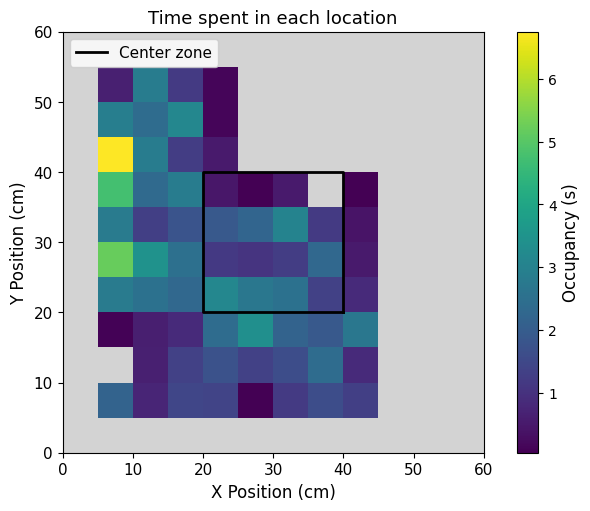

In [7]:
# Select the center zone using its measured coordinates.
regions = Regions(env.regions.values())
regions.add("center", polygon=box(20.0, 20.0, 40.0, 40.0))
env = env.with_regions(regions)
center_mask = regions_to_mask(env, "center")
center_time = occupancy[center_mask].sum()
print(
    f"Time in the center zone: {center_time:.2f} s ({center_time / occupancy.sum():.1%})"
)

fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
env.plot_field(
    np.where(observed, occupancy, np.nan),
    ax=ax,
    cmap="viridis",
    nan_color="lightgray",
    colorbar_label="Occupancy (s)",
)
boundary_x, boundary_y = env.regions["center"].data.exterior.xy
ax.plot(boundary_x, boundary_y, color="black", lw=2, label="Center zone")
ax.set_title("Time spent in each location")
ax.legend(loc="upper left")
plt.show()

Longer dwell times appear in yellow; gray bins were never visited. The animal
spent about one fifth of the recording in the center zone. This summarizes
the recorded trajectory. Testing center preference would also require
accounting for zone area and a suitable behavioral comparison.

A bin belongs to the zone when its center is inside the boundary. With coarser
bins, a zone's represented area can differ from its measured area.

## 6. How much time is available per spatial bin?

Smaller bins resolve finer spatial features but contain less recording time.
Compare three bin widths while keeping the arena and trajectory fixed. This
helps choose a resolution before estimating firing rates.

In [8]:
print("Bin width | Visited / all arena bins | Median occupancy per visited bin")
for bin_width in [2.5, 5.0, 10.0]:
    comparison_edges = np.arange(0.0, 60.0 + bin_width, bin_width)
    n_cells = len(comparison_edges) - 1
    comparison = Environment.from_grid_mask(
        active_mask=np.ones((n_cells, n_cells), dtype=bool),
        grid_edges=(comparison_edges, comparison_edges),
    )
    comparison = comparison.with_metadata(units="cm", frame="arena")
    dwell = comparison.occupancy(times, positions, max_gap=0.1)
    visited = dwell > 0
    print(
        f"{bin_width:5.1f} cm | {visited.sum():4d} / {comparison.n_bins:4d} bins"
        f"    | {np.median(dwell[visited]):.2f} s"
    )

Bin width | Visited / all arena bins | Median occupancy per visited bin
  2.5 cm |  234 /  576 bins    | 0.45 s
  5.0 cm |   66 /  144 bins    | 1.60 s
 10.0 cm |   26 /   36 bins    | 3.80 s


The 2.5 cm bins contain less time per visited bin than the 10 cm bins. All
three analyses use the same recording. A longer recording or repeated visits
may be needed to estimate firing reliably at finer resolution.

## Use your own recording

Replace `times` with increasing timestamps in seconds and `positions` with
one `(x, y)` row per sample. Calibrate camera coordinates into physical units
before analysis. Setting `units="cm"` at construction labels values already in cm; it
does not convert pixels.

Define bins from the measured arena boundary, choose bin width for the spatial
features you want to resolve, and inspect occupancy before proceeding. Set
`max_gap` from the tracking frame rate and expected dropouts. Replace the
center zone with the region relevant to your experiment. After changing the
bins, recalculate position-bin assignments and occupancy together.

Continue with [02: firing-rate maps](02_spatial_rate_maps.ipynb) or
[03: running bouts and track traversals](03_trajectories_and_behavior.ipynb).
The [environment guide](https://edeno.github.io/neurospatial/user-guide/environments/)
covers other arena shapes, and the
[alignment guide](https://edeno.github.io/neurospatial/user-guide/alignment/)
explains camera calibration and matching coordinates across recordings.